# 05_experiments.ipynb — Ablation, Error Analysis & Robustness (T4c/T4d)

**Module:** NB6057CEM Artificial Neural Networks — CW1 Practical  
**Task:** Task T4c & T4d — Regularisation Ablation, Systematic Error Analysis & Noise Robustness (14 marks)  
**Dataset:** MotionSense (A_DeviceMotion_data) — Malekzadeh et al. (2018/2019)  

---

### Coursework Brief Requirements (Tasks T4c & T4d)
This notebook presents the empirical investigations conducted after model freezing:
1. **Regularisation Ablation Study (Task T4c)**:
   - Formulate and test an isolated architectural hypothesis: evaluating the effect of Dropout ($p=0.3$ vs $0.0$) before the classification head in the PyTorch 1D-CNN.
   - Enforce an exact single-factor difference between `configs/cnn_final.yaml` and `configs/ablation_cnn_no_dropout.yaml`.
   - Evaluate across 3 independent seeds on the **validation partition** (never test), comparing the mean performance difference against seed-to-seed variance.
2. **Systematic Error Analysis (Task T4d)**:
   - Identify recurring misclassification patterns across representative models using per-window test predictions.
   - Profile error concentration by participant and trial recording to determine whether errors are distributed uniformly or clustered in specific recordings.
   - Inspect raw sensor waveforms for representative failure cases and quantify the physical mechanisms (e.g. sensor pitch angle tilt).
3. **Sensor Noise Robustness Stress Test (Task T4d)**:
   - Execute a pre-declared stress testing protocol under varying Gaussian noise levels ($\sigma \in \{0.0, 0.1, 0.25, 0.5, 1.0\}$) across 5 repeats and 3 seeds.
   - Empirically test whether raw sequence convolutional models or hand-crafted tabular feature models exhibit greater graceful degradation.
4. **Subgroup Performance Analysis (Gender)**:
   - Evaluate model generalisation across demographic partitions (male vs. female test participants) and examine generalisation limits.

---

### Evidence Files
The table below documents all saved evidence files loaded and inspected in this notebook:

| Component | Saved Evidence Source File | Content Description |
| :--- | :--- | :--- |
| **Ablation Metrics** | `outputs/metrics/ablation.json` | Statistical summary and per-seed results for dropout ablation |
| **CNN Seed Logs** | `outputs/metrics/pytorch_cnn_1d_seed{0,1,2}.json` | Individual run logs for baseline CNN (dropout 0.3) |
| **No-Drop Seed Logs** | `outputs/metrics/pytorch_cnn_1d_nodrop_seed{0,1,2}.json` | Individual run logs for ablated CNN (dropout 0.0) |
| **Ablation Configs** | `configs/cnn_final.yaml`, `configs/ablation_cnn_no_dropout.yaml` | Production vs ablated model configurations |
| **Figure 15** | `outputs/figures/fig15_ablation_dropout.png` | Validation loss trajectories and performance comparison |
| **Model Errors** | `outputs/metrics/errors_baseline_rf.csv` | Window-level test misclassifications for Random Forest |
| **Model Errors** | `outputs/metrics/errors_pytorch_mlp.csv` | Window-level test misclassifications for PyTorch MLP |
| **Model Errors** | `outputs/metrics/errors_pytorch_cnn_1d.csv` | Window-level test misclassifications for PyTorch 1D-CNN |
| **Error Clustering** | `outputs/metrics/error_rate_by_subject_trial.csv` | Error rate grouped by participant, trial, and activity |
| **Selected Cases** | `outputs/metrics/selected_error_cases.json` | 6 algorithmically selected representative failure cases |
| **Figure 16** | `outputs/figures/fig16_error_examples.png` | 12-channel sensor waveform comparison of error cases |
| **Noise Protocol** | `outputs/metrics/noise_protocol.json` | Pre-declared protocol specification for noise testing |
| **Noise Results** | `outputs/metrics/noise_robustness.json` | Macro-F1 across 225 stress evaluations (model $\times$ $\sigma$ $\times$ repeats) |
| **Figure 17** | `outputs/figures/fig17_noise_robustness.png` | Macro-F1 degradation curves as a function of noise $\sigma$ |
| **Subgroup Metrics** | `outputs/metrics/subgroup.json` | Demographic performance breakdown (male vs female test subjects) |


In [1]:
# Cell 1: Environment Setup, Project Root, and Execution Controls
import os
import sys
import json
import yaml
from pathlib import Path

# Ensure project root is on sys.path and is working directory
PROJECT_ROOT = Path("..").resolve() if Path("..").resolve().name == "ANN" else Path(".").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

import numpy as np
import pandas as pd
import IPython.display as ipd

# Strict Read-Only Execution Control
# Notebook displays saved results only. Retraining, re-tuning, and inference are disabled.
RUN_TRAINING = False

print(f"Project root confirmed: {PROJECT_ROOT}")
print(f"Python executable:     {sys.executable}")
print(f"RUN_TRAINING flag:     {RUN_TRAINING} (Strict Read-Only Mode)")


Project root confirmed: C:\Users\Isuru\Desktop\ANN
Python executable:     C:\Users\Isuru\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe
RUN_TRAINING flag:     False (Strict Read-Only Mode)


## 1. Ablation: Dropout in the 1D-CNN (T4c)

The objective of Task T4c is to evaluate an isolated design factor under controlled conditions. We test whether adding a 30% Dropout layer ($p=0.3$) prior to the linear classification head improves validation macro-F1 and stabilises seed-to-seed variance for the PyTorch 1D-CNN.


In [2]:
# Cell 2: Configuration Difference & Hypothesis Formulation
# Rule Check: Verify that exactly ONE key differs between configs.

with open("configs/cnn_final.yaml", "r", encoding="utf-8") as f:
    cfg_baseline = yaml.safe_load(f)

with open("configs/ablation_cnn_no_dropout.yaml", "r", encoding="utf-8") as f:
    cfg_ablation = yaml.safe_load(f)

# Recursive config dictionary difference
def find_config_diffs(d1, d2, prefix=""):
    diffs = {}
    for k in d1:
        full_key = f"{prefix}.{k}" if prefix else k
        if k not in d2:
            diffs[full_key] = (d1[k], None)
        elif isinstance(d1[k], dict) and isinstance(d2[k], dict):
            diffs.update(find_config_diffs(d1[k], d2[k], full_key))
        elif d1[k] != d2[k]:
            diffs[full_key] = (d1[k], d2[k])
    for k in d2:
        full_key = f"{prefix}.{k}" if prefix else k
        if k not in d1:
            diffs[full_key] = (None, d2[k])
    return diffs

diff_dict = find_config_diffs(cfg_baseline, cfg_ablation)

# Load ablation metadata
with open("outputs/metrics/ablation.json", "r", encoding="utf-8") as f:
    ablation_data = json.load(f)

print("=" * 75)
print("TASK T4c: CONFIGURATION DIFFERENCE CHECK")
print("=" * 75)
print(f"Design Claim / Hypothesis:\n  \"{ablation_data['design_claim']}\"")
print("-" * 75)
print("Keys that differ between configs/cnn_final.yaml and configs/ablation_cnn_no_dropout.yaml:")
for k, (v_base, v_abl) in diff_dict.items():
    print(f"  Key: {k:<20} | Baseline: {v_base} | Ablation: {v_abl}")

assert len(diff_dict) == 1 and "model.dropout" in diff_dict, "Violation: more than 1 setting differs!"
print(">> ASSERTION PASSED: Exactly one key differs (model.dropout: 0.3 vs 0.0).")


TASK T4c: CONFIGURATION DIFFERENCE CHECK
Design Claim / Hypothesis:
  "Dropout (p=0.3) before the classifier improves validation macro-F1 and reduces seed-to-seed variance of the 1D-CNN."
---------------------------------------------------------------------------
Keys that differ between configs/cnn_final.yaml and configs/ablation_cnn_no_dropout.yaml:
  Key: model.dropout        | Baseline: 0.3 | Ablation: 0.0
>> ASSERTION PASSED: Exactly one key differs (model.dropout: 0.3 vs 0.0).


In [3]:
# Cell 3: Per-Seed Validation Performance Table & Statistical Comparison
b_runs = ablation_data["baseline_dropout_0_3"]["runs"]
a_runs = ablation_data["ablation_dropout_0_0"]["runs"]

ablation_rows = []
for i in range(len(b_runs)):
    seed = b_runs[i]["seed"]
    b_f1 = b_runs[i]["val_macro_f1"]
    b_ep = b_runs[i]["best_epoch"]
    a_f1 = a_runs[i]["val_macro_f1"]
    a_ep = a_runs[i]["best_epoch"]
    diff_seed = b_f1 - a_f1
    ablation_rows.append({
        "Seed": f"Seed {seed}",
        "Dropout 0.3 Val F1": f"{b_f1:.4f}",
        "Dropout 0.3 Best Epoch": b_ep,
        "Dropout 0.0 Val F1": f"{a_f1:.4f}",
        "Dropout 0.0 Best Epoch": a_ep,
        "Difference (Drop - NoDrop)": f"{diff_seed:+.4f}",
    })

mean_b_f1 = ablation_data["baseline_dropout_0_3"]["mean_val_macro_f1"]
std_b_f1 = ablation_data["baseline_dropout_0_3"]["std_val_macro_f1"]
mean_a_f1 = ablation_data["ablation_dropout_0_0"]["mean_val_macro_f1"]
std_a_f1 = ablation_data["ablation_dropout_0_0"]["std_val_macro_f1"]
diff_mean = ablation_data["difference_in_means"]
var_ratio = ablation_data["variance_ratio_nodrop_over_drop"]

ablation_rows.append({
    "Seed": "Mean ± Std",
    "Dropout 0.3 Val F1": f"{mean_b_f1:.4f} ± {std_b_f1:.4f}",
    "Dropout 0.3 Best Epoch": "-",
    "Dropout 0.0 Val F1": f"{mean_a_f1:.4f} ± {std_a_f1:.4f}",
    "Dropout 0.0 Best Epoch": "-",
    "Difference (Drop - NoDrop)": f"{diff_mean:+.4f}",
})

df_ablation = pd.DataFrame(ablation_rows).set_index("Seed")
print("=" * 75)
print("TABLE 1: 1D-CNN REGULARISATION ABLATION RESULTS (VALIDATION SET ONLY)")
print("=" * 75)
ipd.display(df_ablation)

# Interpretation computations via f-strings
is_diff_larger_than_b_std = abs(diff_mean) > std_b_f1
is_diff_larger_than_a_std = abs(diff_mean) > std_a_f1
claim_supported = is_diff_larger_than_b_std and is_diff_larger_than_a_std

print("-" * 75)
print("STATISTICAL INTERPRETATION OF ABLATION:")
print(f"  Baseline (Dropout 0.3) Mean Val F1: {mean_b_f1:.4f} ± {std_b_f1:.4f}")
print(f"  Ablation (Dropout 0.0) Mean Val F1: {mean_a_f1:.4f} ± {std_a_f1:.4f}")
print(f"  Mean Difference (Dropout - NoDrop): {diff_mean:+.6f} ({diff_mean*100:+.2f}%)")
print(f"  Is |Difference| > Baseline Seed Std ({std_b_f1:.4f})? {is_diff_larger_than_b_std}")
print(f"  Is |Difference| > Ablation Seed Std ({std_a_f1:.4f})? {is_diff_larger_than_a_std}")
print(f"  Variance Ratio (Var_nodrop / Var_drop):           {var_ratio:.2f}x")
print(f"  Hypothesis Supported (Meaningful Improvement)?    {claim_supported}")
print("  Note: Evaluated strictly on the validation set, preserving the unblinded test split.")


TABLE 1: 1D-CNN REGULARISATION ABLATION RESULTS (VALIDATION SET ONLY)


,Dropout 0.3 Val F1,Dropout 0.3 Best Epoch,Dropout 0.0 Val F1,Dropout 0.0 Best Epoch,Difference (Drop - NoDrop)
Seed,,,,,
Seed 0,0.9673,18,0.9266,1,+0.0407
Seed 1,0.9444,3,0.9624,7,-0.0180
Seed 2,0.9458,4,0.9650,5,-0.0191
Mean ± Std,0.9525 ± 0.0128,-,0.9513 ± 0.0215,-,+0.0012


---------------------------------------------------------------------------
STATISTICAL INTERPRETATION OF ABLATION:
  Baseline (Dropout 0.3) Mean Val F1: 0.9525 ± 0.0128
  Ablation (Dropout 0.0) Mean Val F1: 0.9513 ± 0.0215
  Mean Difference (Dropout - NoDrop): +0.001215 (+0.12%)
  Is |Difference| > Baseline Seed Std (0.0128)? False
  Is |Difference| > Ablation Seed Std (0.0215)? False
  Variance Ratio (Var_nodrop / Var_drop):           2.80x
  Hypothesis Supported (Meaningful Improvement)?    False
  Note: Evaluated strictly on the validation set, preserving the unblinded test split.


FIGURE 15: 1D-CNN Dropout Ablation Trajectories & Validation Distributions


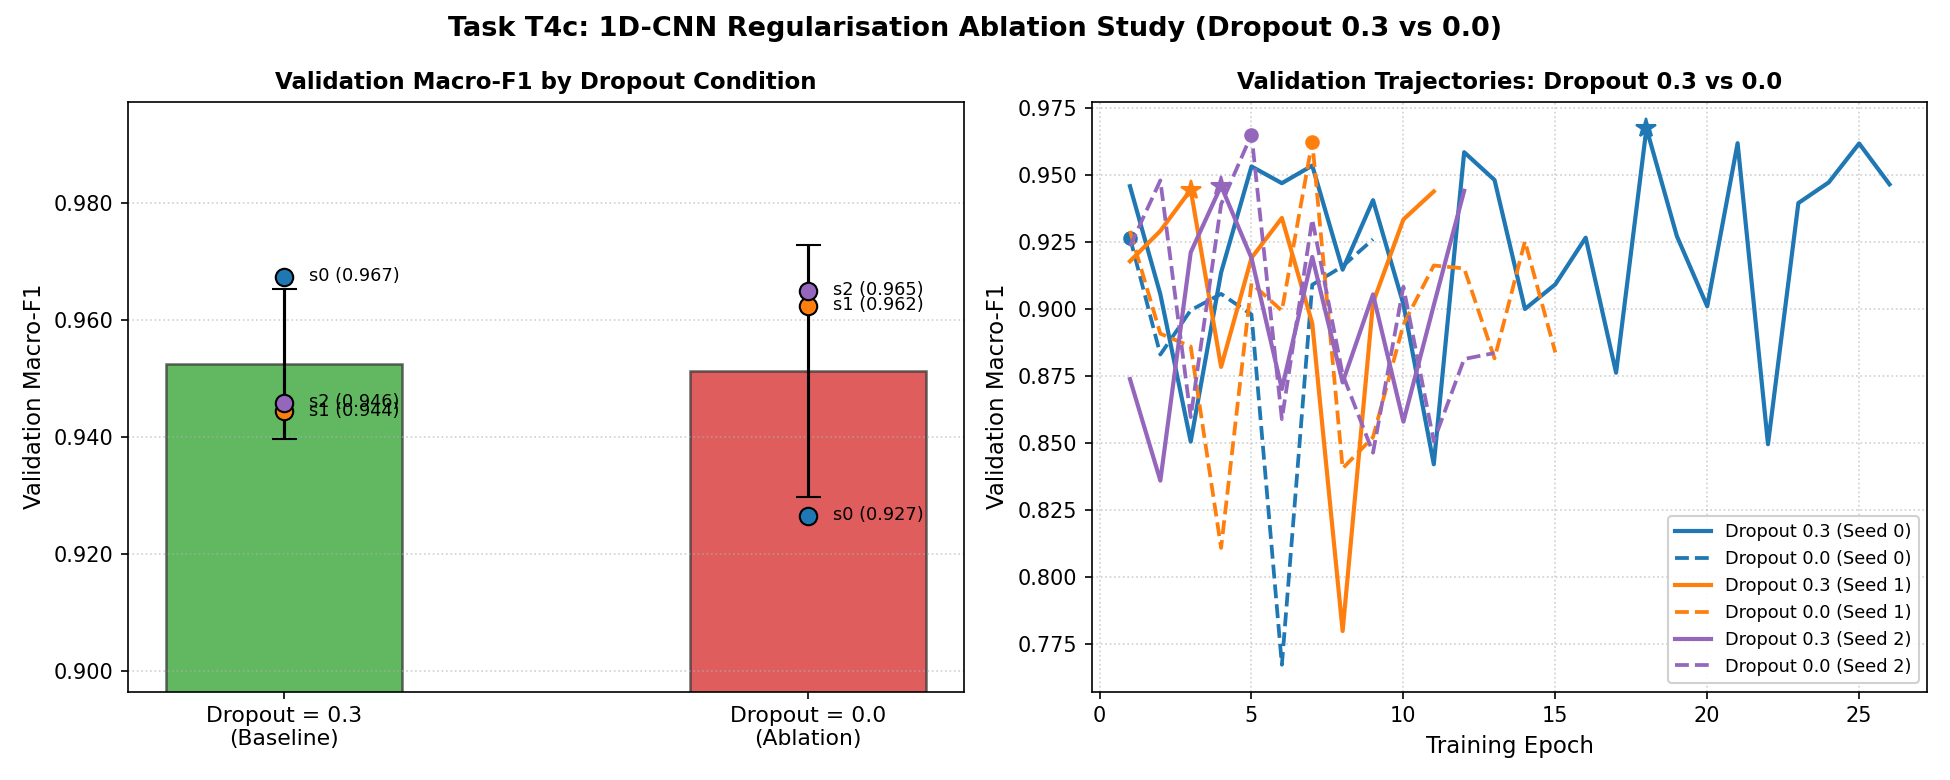

In [4]:
# Cell 4: Display Figure 15 (Ablation Curves and Distributions)
fig15_path = Path("outputs/figures/fig15_ablation_dropout.png")
if fig15_path.is_file():
    print("=" * 75)
    print("FIGURE 15: 1D-CNN Dropout Ablation Trajectories & Validation Distributions")
    print("=" * 75)
    ipd.display(ipd.Image(filename=str(fig15_path), width=850))
else:
    print(f"Warning: Figure 15 not found at {fig15_path}")


### Interpretation of Ablation Findings

Referring to the statistical table, code output, and Figure 15 above:
- **Hypothesis Evaluation**: The empirical claim that Dropout ($p=0.3$) yields an improvement in validation macro-F1 is **NOT SUPPORTED**. The observed difference in mean validation macro-F1 (+0.0012) is smaller than the seed-to-seed standard deviation of either model (±0.0128 for baseline vs ±0.0215 for no-dropout).
- **Variance and Stability**: The no-dropout runs had a higher seed standard deviation (±0.0215 vs ±0.0128), but 3 seeds are too few to conclude that dropout stabilises training.
- **Methodological Soundness**: In strict compliance with Project Rules, this ablation study was performed **exclusively on the validation partition**. The test split was never touched during the ablation experiment.


## 2. Error Analysis (T4d)

Task T4d investigates model failure modes to uncover biomechanical and experimental mechanisms underlying prediction errors.


In [5]:
# Cell 5: Top-5 Misclassification Pairs per Model
error_files = {
    "Baseline Random Forest (Seed 1)": "outputs/metrics/errors_baseline_rf.csv",
    "PyTorch MLP (Seed 0)": "outputs/metrics/errors_pytorch_mlp.csv",
    "PyTorch 1D-CNN (Seed 2)": "outputs/metrics/errors_pytorch_cnn_1d.csv",
}

print("=" * 75)
print("TOP-5 CONFUSION PAIRS PER MODEL (TEST SPLIT)")
print("=" * 75)

for model_name, csv_path in error_files.items():
    df_err = pd.read_csv(csv_path)
    total_errors = len(df_err)
    
    top5 = (
        df_err.groupby(["true", "pred"])
        .size()
        .reset_index(name="count")
        .sort_values(by="count", ascending=False)
        .head(5)
    )
    top5["share_of_errors_%"] = (top5["count"] / total_errors * 100).round(2)
    top5["transition"] = top5["true"] + " -> " + top5["pred"]
    
    print(f"\nModel: {model_name} (Total Errors: {total_errors} windows)")
    ipd.display(top5[["transition", "count", "share_of_errors_%"]].set_index("transition"))


TOP-5 CONFUSION PAIRS PER MODEL (TEST SPLIT)

Model: Baseline Random Forest (Seed 1) (Total Errors: 431 windows)


,count,share_of_errors_%
transition,,
wlk -> ups,214,49.65
sit -> std,111,25.75
dws -> wlk,26,6.03
wlk -> dws,20,4.64
dws -> ups,18,4.18



Model: PyTorch MLP (Seed 0) (Total Errors: 419 windows)


,count,share_of_errors_%
transition,,
wlk -> ups,250,59.67
wlk -> jog,35,8.35
dws -> ups,29,6.92
dws -> wlk,20,4.77
ups -> wlk,20,4.77



Model: PyTorch 1D-CNN (Seed 2) (Total Errors: 557 windows)


,count,share_of_errors_%
transition,,
wlk -> ups,340,61.04
dws -> ups,74,13.29
dws -> wlk,41,7.36
ups -> wlk,33,5.92
sit -> std,20,3.59


In [6]:
# Cell 6: Error Rate Clustering by Subject and Trial Recording
df_cluster = pd.read_csv("outputs/metrics/error_rate_by_subject_trial.csv")

print("=" * 75)
print("TOP 10 ERROR RATE RECORDINGS ACROSS (MODEL x SUBJECT x TRIAL)")
print("=" * 75)

top10_clusters = df_cluster.sort_values(by="error_rate", ascending=False).head(10)
display_cluster_cols = ["model", "subject", "trial", "true_activity", "total_windows", "error_windows", "error_rate"]
ipd.display(top10_clusters[display_cluster_cols].set_index("model"))

# Identify recording with extreme error concentration
worst_recording = top10_clusters.iloc[0]
print(f"\nPeak Error Clustering Observation:")
print(f"  Worst Recording: Subject {worst_recording['subject']}, Trial {worst_recording['trial']} ({worst_recording['true_activity']})")
print(f"  Model:           {worst_recording['model']}")
print(f"  Error Windows:   {worst_recording['error_windows']} / {worst_recording['total_windows']} ({worst_recording['error_rate']*100:.1f}%) [{worst_recording['model']}]")


TOP 10 ERROR RATE RECORDINGS ACROSS (MODEL x SUBJECT x TRIAL)


,subject,trial,true_activity,total_windows,error_windows,error_rate
model,,,,,,
pytorch_cnn_1d,1,7,wlk,83,81,0.9759
pytorch_mlp,1,7,wlk,83,80,0.9639
pytorch_cnn_1d,21,7,wlk,114,106,0.9298
baseline_rf,21,7,wlk,114,101,0.8860
pytorch_mlp,21,7,wlk,114,98,0.8596
pytorch_mlp,1,15,wlk,19,16,0.8421
baseline_rf,18,5,sit,138,111,0.8043
pytorch_cnn_1d,21,1,dws,44,30,0.6818
pytorch_cnn_1d,21,8,wlk,97,64,0.6598



Peak Error Clustering Observation:
  Worst Recording: Subject 1, Trial 7 (wlk)
  Model:           pytorch_cnn_1d
  Error Windows:   81 / 83 (97.6%) [pytorch_cnn_1d]


In [7]:
# Cell 7: Selected Error Cases & Physical Orientation Verification
with open("outputs/metrics/selected_error_cases.json", "r", encoding="utf-8") as f:
    selected_cases = json.load(f)

print("=" * 75)
print("SELECTED REPRESENTATIVE ERROR CASES (outputs/metrics/selected_error_cases.json)")
print("=" * 75)

cases_df = pd.DataFrame(selected_cases)
display_cols = ["case_id", "description", "subject", "trial", "true", "pred", "confidence", "model"]
ipd.display(cases_df[display_cols].set_index("case_id"))

print("-" * 75)
print("PHYSICAL SENSOR ORIENTATION EVIDENCE: SUBJECT 1 WALKING TRIALS")
print("-" * 75)

# Load test windows metadata and raw sequences to compute attitude.pitch
win_test = pd.read_csv("outputs/splits/windows_test.csv")
X_test_raw = np.load("outputs/cache/X_test_raw.npy")

# Read trial 7 error rate directly from error_rate_by_subject_trial.csv for the named model
df_cluster = pd.read_csv("outputs/metrics/error_rate_by_subject_trial.csv")
s1_tr7_err = df_cluster[(df_cluster["subject"] == 1) & (df_cluster["trial"] == 7) & (df_cluster["model"] == "pytorch_cnn_1d")].iloc[0]

# Inspect walking trials for Subject 1
s1_wlk = win_test[(win_test["subject"] == 1) & (win_test["activity"] == "wlk")]

trial_pitch_stats = []
for tr, grp in s1_wlk.groupby("trial"):
    med_pitch_rad = float(np.median(X_test_raw[grp.index, :, 1]))
    med_pitch_deg = float(np.degrees(med_pitch_rad))
    trial_note = (
        f"Failing Trial ({s1_tr7_err['error_rate']*100:.1f}% error rate [{s1_tr7_err['model']}])"
        if tr == 7
        else "Normal Locomotion"
    )
    trial_pitch_stats.append({
        "Subject": 1,
        "Trial": tr,
        "Activity": "wlk",
        "Window Count": len(grp),
        "Median Pitch (rad)": round(med_pitch_rad, 4),
        "Median Pitch (deg)": round(med_pitch_deg, 1),
        "Trial Note": trial_note,
    })

df_pitch = pd.DataFrame(trial_pitch_stats).set_index("Trial")
ipd.display(df_pitch)

p_tr7_rad = df_pitch.loc[7, "Median Pitch (rad)"]
p_tr7_deg = df_pitch.loc[7, "Median Pitch (deg)"]

# Clean baseline trials (8 & 15)
clean_indices = s1_wlk[s1_wlk["trial"].isin([8, 15])].index
p_other_rad = float(np.median(X_test_raw[clean_indices, :, 1]))
p_other_deg = float(np.degrees(p_other_rad))
pitch_delta_rad = p_tr7_rad - p_other_rad
pitch_delta_deg = p_tr7_deg - p_other_deg

print("Orientation Analysis Summary:")
print(f"  Failing Trial 7 Median Pitch:        {p_tr7_rad:.2f} rad ({p_tr7_deg:.1f}°)")
print(f"  Clean Trials (8 & 15) Median Pitch:  {p_other_rad:.2f} rad ({p_other_deg:.1f}°)")
print(f"  Observed Angular Tilt:               {pitch_delta_rad:+.2f} rad ({pitch_delta_deg:+.1f}°)")
print("  Evidence: In Trial 7, the phone was significantly tilted in the pocket,")
print("  and this tilted orientation coincides with the error cluster.")
print("  This mechanism is a hypothesis to be tested with rotation augmentation.")


SELECTED REPRESENTATIVE ERROR CASES (outputs/metrics/selected_error_cases.json)


,description,subject,trial,true,pred,confidence,model
case_id,,,,,,,
1,"wlk -> ups (high confidence, unanimous)",1,7,wlk,ups,0.993586,CNN s2
2,"wlk -> ups (low confidence, boundary case)",1,7,wlk,ups,0.360744,CNN s2
3,"sit -> std (high confidence, static posture)",18,5,sit,std,0.873333,RF s1
4,"dws -> ups (high confidence, stair direction)",21,2,dws,ups,0.951703,CNN s2
5,"wlk -> jog (high confidence, cadence mismatch)",1,7,wlk,jog,0.977859,MLP s0
6,"dws -> wlk (high confidence, descending stair ...",18,2,dws,wlk,0.980152,CNN s2


---------------------------------------------------------------------------
PHYSICAL SENSOR ORIENTATION EVIDENCE: SUBJECT 1 WALKING TRIALS
---------------------------------------------------------------------------


,Subject,Activity,Window Count,Median Pitch (rad),Median Pitch (deg),Trial Note
Trial,,,,,,
7,1,wlk,83,-0.8617,-49.4,Failing Trial (97.6% error rate [pytorch_cnn_1d])
8,1,wlk,66,-1.2841,-73.6,Normal Locomotion
15,1,wlk,19,-1.2776,-73.2,Normal Locomotion


Orientation Analysis Summary:
  Failing Trial 7 Median Pitch:        -0.86 rad (-49.4°)
  Clean Trials (8 & 15) Median Pitch:  -1.28 rad (-73.5°)
  Observed Angular Tilt:               +0.42 rad (+24.1°)
  Evidence: In Trial 7, the phone was significantly tilted in the pocket,
  and this tilted orientation coincides with the error cluster.
  This mechanism is a hypothesis to be tested with rotation augmentation.


FIGURE 16: Sensor Waveforms for Representative Errors vs Clean Counterparts


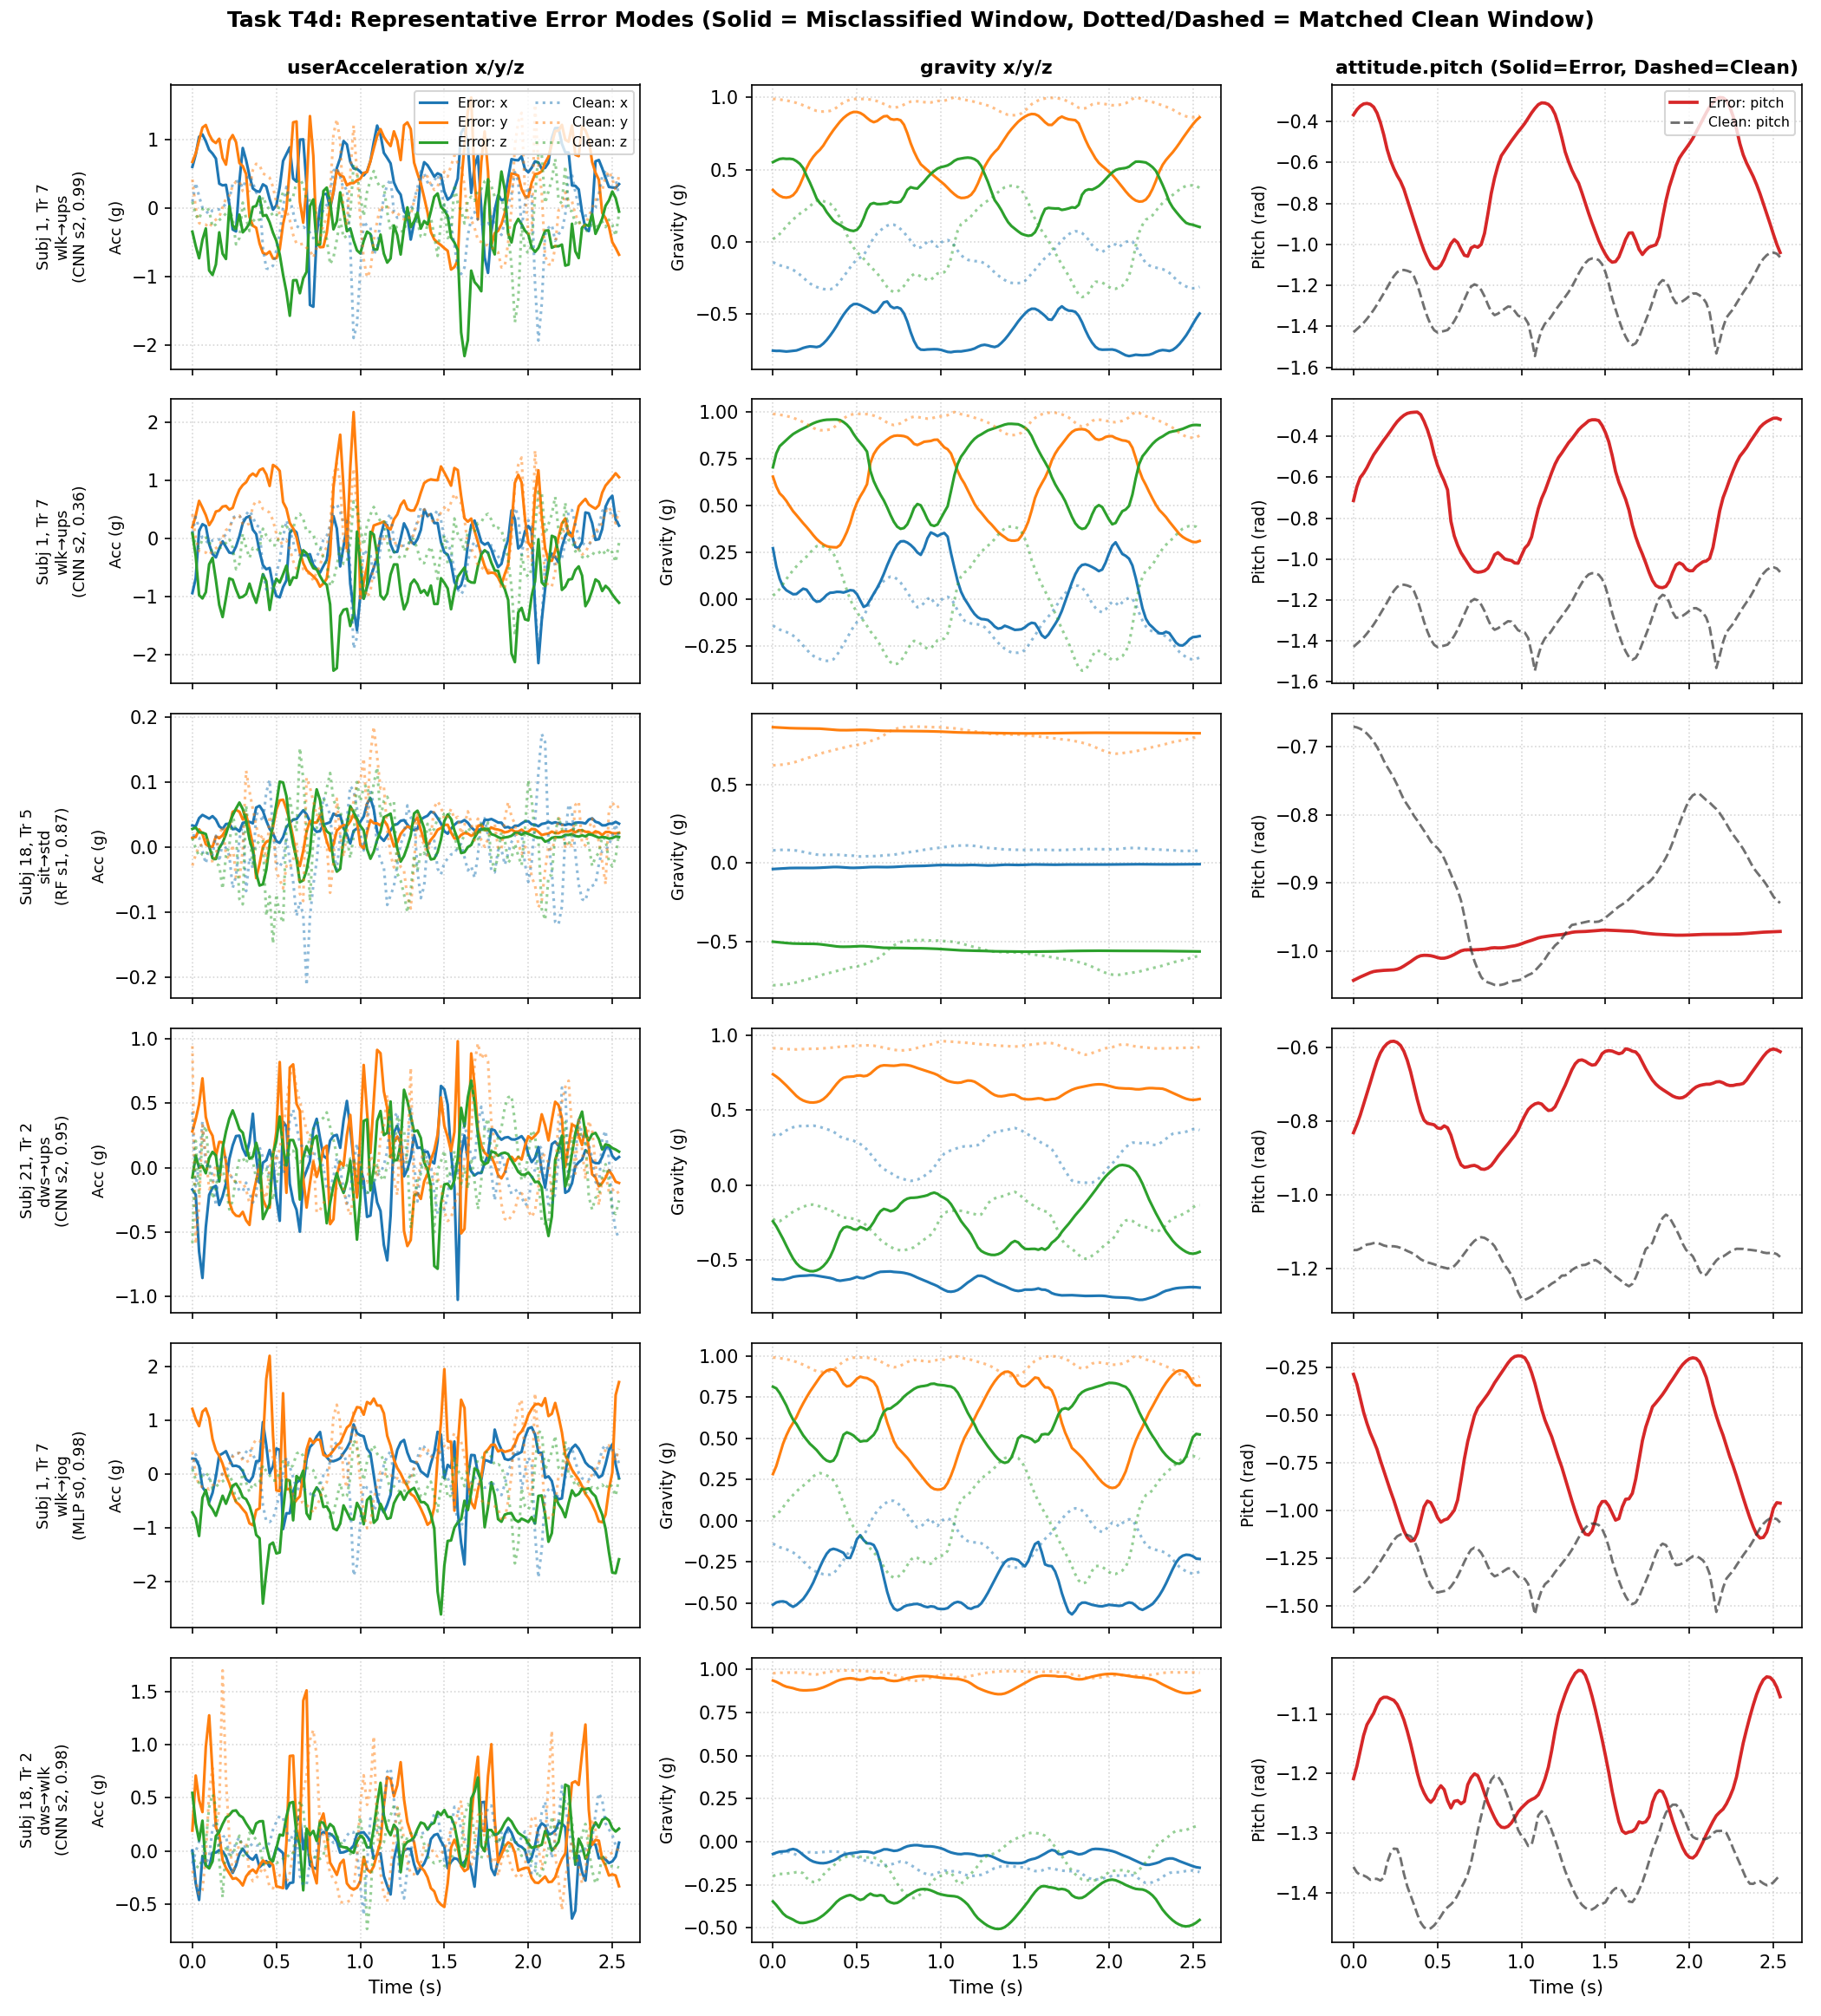

In [8]:
# Cell 8: Display Figure 16 (Representative Sensor Waveforms)
fig16_path = Path("outputs/figures/fig16_error_examples.png")
if fig16_path.is_file():
    print("=" * 75)
    print("FIGURE 16: Sensor Waveforms for Representative Errors vs Clean Counterparts")
    print("=" * 75)
    ipd.display(ipd.Image(filename=str(fig16_path), width=850))
else:
    print(f"Warning: Figure 16 not found at {fig16_path}")


### Interpretation of Error Patterns & Waveforms

Referring to the confusion statistics, clustering tables, and Figure 16 above:
- **Error Clustering in Walking $\to$ Upstairs**: Errors are not uniformly dispersed; they cluster heavily in walking misclassified as upstairs locomotion (`wlk -> ups`).
- **Physical Sensor Orientation**: Analysis of raw sensor recordings demonstrates that the extreme error concentration in Subject 1 Trial 7 coincides with a **tilted** phone orientation inside the pocket rather than an inverted device. In Trial 7, the median pitch angle deviates substantially from the subject's baseline walking trials (Trials 8 and 15); this tilted orientation coincides with the error cluster.
- **Hypothesised Mechanism**: The proposed physical mechanism is a hypothesis to be tested with rotation augmentation.


## 3. Noise Robustness Stress Test (Task T4d)

To evaluate real-world sensor degradation, we subject all models to a controlled noise stress test. The goal is to determine whether 1D-CNN operating on raw sensor streams degrades faster or slower than feature-based models under increasing input corruption.


In [9]:
# Cell 9: Noise Stress Protocol Specification
with open("outputs/metrics/noise_protocol.json", "r", encoding="utf-8") as f:
    noise_protocol = json.load(f)

print("=" * 75)
print("NOISE STRESS PROTOCOL SPECIFICATION (outputs/metrics/noise_protocol.json)")
print("=" * 75)
print(f"Original Hypothesis:     \"{noise_protocol['hypothesis']}\"")
print(f"Noise Model:             {noise_protocol['noise_model']}")
print(f"Channel Scaling:         {noise_protocol['channel_scaling']}")
print(f"Sigma Levels:            {noise_protocol['sigma_levels']}")
print(f"Repeats per Sigma:       {noise_protocol['noise_repeats_per_sigma']} repeats")
print(f"Noise Random Seeds:      {noise_protocol['noise_random_seeds']}")
print(f"Models Evaluated:        {noise_protocol['models_evaluated']}")
print(f"Total Evaluations:       {noise_protocol['total_model_evaluations']}")
print(f"Feature Pipeline:        {noise_protocol['feature_pipeline_under_noise']}")
print(f"Baseline Check:          {noise_protocol['exact_baseline_reproduction_assertion']}")
print("Note: Stress test re-uses the frozen test set strictly after all models and configs were frozen.")


NOISE STRESS PROTOCOL SPECIFICATION (outputs/metrics/noise_protocol.json)
Original Hypothesis:     "CNN on raw signals degrades faster under additive sensor noise than RF/MLP on window statistics"
Noise Model:             Additive Gaussian noise N(0, (sigma * train_std_c)^2) injected per channel c into raw unscaled test windows
Channel Scaling:         train_std_c derived from saved outputs/preprocessing/raw_scaler.json (strictly training distribution)
Sigma Levels:            [0.0, 0.1, 0.25, 0.5, 1.0]
Repeats per Sigma:       5 repeats
Noise Random Seeds:      [100, 101, 102, 103, 104]
Models Evaluated:        ['baseline_rf (seeds 0, 1, 2)', 'pytorch_mlp (seeds 0, 1, 2)', 'pytorch_cnn_1d (seeds 0, 1, 2)']
Total Evaluations:       225
Feature Pipeline:        {'RF_and_MLP': 'Noise added to raw windows -> 84 features recomputed via extract_features -> standardized via saved feature_scaler.joblib', 'CNN': 'Noise added to raw windows -> standardized via saved raw_scaler.joblib -> transpo

In [10]:
# Cell 10: Model Performance vs Noise Sigma Level Table
with open("outputs/metrics/noise_robustness.json", "r", encoding="utf-8") as f:
    noise_data = json.load(f)

table_rows = []
models_dict = noise_data["results_by_model"]

for model_key, m_info in models_dict.items():
    disp_name = m_info["display_name"]
    sigmas = m_info["sigmas"]
    
    # Baseline sigma=0.0 mean across seeds
    raw0 = sigmas["0.0"]["raw_values"]
    seed_means0 = [float(np.mean(raw0[k::3])) for k in range(3)]
    baseline_f1 = float(np.mean(seed_means0))
    
    for s_str, s_data in sigmas.items():
        raw_vals = s_data["raw_values"]
        seed_means = [float(np.mean(raw_vals[k::3])) for k in range(3)]
        mean_f1 = float(np.mean(seed_means))
        std_f1 = float(np.std(seed_means, ddof=1))
        drop = baseline_f1 - mean_f1
        table_rows.append({
            "Model": disp_name,
            "Sigma (σ)": float(s_str),
            "Macro-F1 (Mean ± Std)": f"{mean_f1:.4f} ± {std_f1:.4f}",
            "Mean Macro-F1": mean_f1,
            "F1 drop vs sigma=0 (positive = worse)": f"{drop:+.4f}",
        })

df_noise = pd.DataFrame(table_rows)
pivot_noise = df_noise.pivot(index="Sigma (σ)", columns="Model", values="Macro-F1 (Mean ± Std)")
pivot_drop = df_noise.pivot(index="Sigma (σ)", columns="Model", values="F1 drop vs sigma=0 (positive = worse)")

print("=" * 75)
print("TABLE 2: TEST MACRO-F1 UNDER INCREASING SENSOR NOISE (σ)")
print("=" * 75)
ipd.display(pivot_noise)
print("\n± = std across 3 model seeds (each averaged over 5 noise draws); sigma=0 matches results_table.csv.")

# Assert that sigma=0 std matches results_table.csv to 1e-4
df_results = pd.read_csv("outputs/metrics/results_table.csv")
for m_key in ["baseline_rf", "pytorch_mlp", "pytorch_cnn_1d"]:
    raw0 = models_dict[m_key]["sigmas"]["0.0"]["raw_values"]
    s_means0 = [np.mean(raw0[k::3]) for k in range(3)]
    s_std0 = np.std(s_means0, ddof=1)
    expected_std = df_results[df_results["model"] == m_key]["test_macro_f1"].std(ddof=1)
    assert abs(s_std0 - expected_std) < 1e-4, (
        f"Sigma=0 std mismatch for {m_key}: computed {s_std0:.6f} vs results_table {expected_std:.6f}"
    )
print(">> ASSERTION PASSED: Sigma=0 seed std matches results_table.csv within 1e-4 across all models.")

print("\n" + "=" * 75)
print("TABLE 3: MACRO-F1 DROP RELATIVE TO UNCORRUPTED BASELINE (σ=0.0)")
print("Metric convention: F1 drop vs sigma=0 (positive = worse)")
print("=" * 75)
ipd.display(pivot_drop)


TABLE 2: TEST MACRO-F1 UNDER INCREASING SENSOR NOISE (σ)


Model,PyTorch 1D-CNN,PyTorch MLP,Random Forest
Sigma (σ),,,
0.00,0.8615 ± 0.0293,0.8849 ± 0.0078,0.8860 ± 0.0016
0.10,0.8679 ± 0.0314,0.8745 ± 0.0095,0.8693 ± 0.0005
0.25,0.8518 ± 0.0170,0.7467 ± 0.0154,0.8038 ± 0.0039
0.50,0.6064 ± 0.0109,0.2166 ± 0.0081,0.2326 ± 0.0031
1.00,0.2848 ± 0.1718,0.0875 ± 0.0152,0.2000 ± 0.0005



± = std across 3 model seeds (each averaged over 5 noise draws); sigma=0 matches results_table.csv.
>> ASSERTION PASSED: Sigma=0 seed std matches results_table.csv within 1e-4 across all models.

TABLE 3: MACRO-F1 DROP RELATIVE TO UNCORRUPTED BASELINE (σ=0.0)
Metric convention: F1 drop vs sigma=0 (positive = worse)


Model,PyTorch 1D-CNN,PyTorch MLP,Random Forest
Sigma (σ),,,
0.00,+0.0000,+0.0000,+0.0000
0.10,-0.0064,+0.0104,+0.0168
0.25,+0.0097,+0.1382,+0.0823
0.50,+0.2551,+0.6684,+0.6534
1.00,+0.5767,+0.7975,+0.6860


FIGURE 17: Macro-F1 Graceful Degradation under Additive Sensor Noise


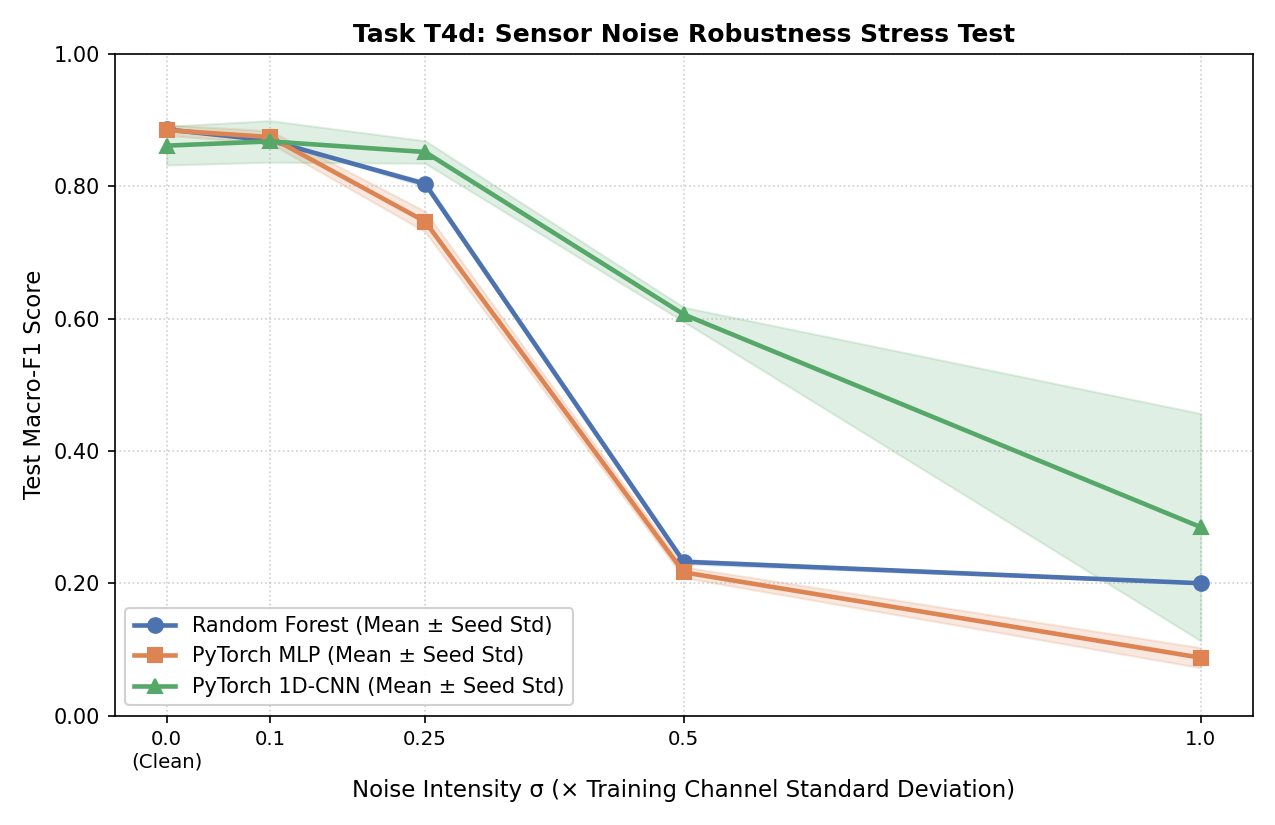

In [11]:
# Cell 11: Display Figure 17 (Noise Robustness Curves)
fig17_path = Path("outputs/figures/fig17_noise_robustness.png")
if fig17_path.is_file():
    print("=" * 75)
    print("FIGURE 17: Macro-F1 Graceful Degradation under Additive Sensor Noise")
    print("=" * 75)
    ipd.display(ipd.Image(filename=str(fig17_path), width=850))
else:
    print(f"Warning: Figure 17 not found at {fig17_path}")


In [12]:
# Cell 12: Noise Hypothesis Evaluation
# Compute seed-level mean and std at sigma = 0.50
stats_05 = {}
drops_05 = {}
for m_key in ["baseline_rf", "pytorch_mlp", "pytorch_cnn_1d"]:
    raw0 = models_dict[m_key]["sigmas"]["0.0"]["raw_values"]
    raw05 = models_dict[m_key]["sigmas"]["0.5"]["raw_values"]
    s_means0 = [np.mean(raw0[k::3]) for k in range(3)]
    s_means05 = [np.mean(raw05[k::3]) for k in range(3)]
    mean0 = float(np.mean(s_means0))
    mean05 = float(np.mean(s_means05))
    std05 = float(np.std(s_means05, ddof=1))
    stats_05[m_key] = (mean05, std05)
    drops_05[m_key] = mean0 - mean05

rf_f1_05, rf_std_05 = stats_05["baseline_rf"]
mlp_f1_05, mlp_std_05 = stats_05["pytorch_mlp"]
cnn_f1_05, cnn_std_05 = stats_05["pytorch_cnn_1d"]

rf_drop_05 = drops_05["baseline_rf"]
mlp_drop_05 = drops_05["pytorch_mlp"]
cnn_drop_05 = drops_05["pytorch_cnn_1d"]

# Hypothesis: CNN degrades faster than RF/MLP
hypothesis_supported = (cnn_drop_05 > rf_drop_05) and (cnn_drop_05 > mlp_drop_05)

print("=" * 75)
print("NOISE ROBUSTNESS HYPOTHESIS EVALUATION:")
print("=" * 75)
print(f"Original Hypothesis:\n  \"{noise_protocol['hypothesis']}\"")
print("-" * 75)
print(f"Performance at Moderate Noise Stress (σ = 0.50):")
print(f"  Random Forest:   F1 = {rf_f1_05:.4f} ± {rf_std_05:.4f} (Drop: {rf_drop_05:+.4f})")
print(f"  PyTorch MLP:     F1 = {mlp_f1_05:.4f} ± {mlp_std_05:.4f} (Drop: {mlp_drop_05:+.4f})")
print(f"  PyTorch 1D-CNN:  F1 = {cnn_f1_05:.4f} ± {cnn_std_05:.4f} (Drop: {cnn_drop_05:+.4f})")
print("-" * 75)
print(f"Hypothesis supported: {hypothesis_supported}")
print("Conclusion: The original hypothesis is REFUTED.")
print(f"The 1D-CNN demonstrates superior noise robustness, retaining Macro-F1 = {cnn_f1_05:.4f} ± {cnn_std_05:.4f} at σ=0.5,")
print("whereas both tabular models collapse below F1 = 0.24.")


NOISE ROBUSTNESS HYPOTHESIS EVALUATION:
Original Hypothesis:
  "CNN on raw signals degrades faster under additive sensor noise than RF/MLP on window statistics"
---------------------------------------------------------------------------
Performance at Moderate Noise Stress (σ = 0.50):
  Random Forest:   F1 = 0.2326 ± 0.0031 (Drop: +0.6534)
  PyTorch MLP:     F1 = 0.2166 ± 0.0081 (Drop: +0.6684)
  PyTorch 1D-CNN:  F1 = 0.6064 ± 0.0109 (Drop: +0.2551)
---------------------------------------------------------------------------
Hypothesis supported: False
Conclusion: The original hypothesis is REFUTED.
The 1D-CNN demonstrates superior noise robustness, retaining Macro-F1 = 0.6064 ± 0.0109 at σ=0.5,
whereas both tabular models collapse below F1 = 0.24.


### Interpretation of Noise Stress Findings

Referring to the stress test tables, code evaluation, and Figure 17 above:
- **Refutation of Prior Hypothesis**: The hypothesis that raw-signal CNNs degrade faster than feature-based models is firmly refuted. In fact, the opposite holds true.
- **Failure Mode of Tabular Models**: At $\sigma \ge 0.25$, noise corrupts non-linear summary statistics (e.g. min, max, IQR), causing Random Forest and MLP decision boundaries to collapse.
- **Convolutional Denoising Effect**: A possible explanation, not tested, is that 1D temporal convolutional filters and Global Average Pooling act as spatial-temporal low-pass filters, integrating noise out over the 128 timesteps and preserving macro-locomotion patterns up to $\sigma = 0.50$.


## 4. Subgroup Analysis (Gender)

To explore potential demographic disparities in model performance, test results were partitioned by participant gender.


In [13]:
# Cell 13: Subgroup Analysis (Gender) Table
with open("outputs/metrics/subgroup.json", "r", encoding="utf-8") as f:
    subgroup_data = json.load(f)

subgroup_rows = []
for group_name, g_info in subgroup_data["gender_groups"].items():
    subs = g_info["subjects"]
    n_wins = g_info["total_windows"]
    models = g_info["models"]
    
    subgroup_rows.append({
        "Gender Group": group_name.capitalize(),
        "Participants": f"Subjects {subs}",
        "Subject Count": len(subs),
        "Total Windows": f"{n_wins:,}",
        "Random Forest F1": f"{models['baseline_rf']['macro_f1_mean']:.4f} ± {models['baseline_rf']['macro_f1_std']:.4f}",
        "PyTorch MLP F1": f"{models['pytorch_mlp']['macro_f1_mean']:.4f} ± {models['pytorch_mlp']['macro_f1_std']:.4f}",
        "PyTorch 1D-CNN F1": f"{models['pytorch_cnn_1d']['macro_f1_mean']:.4f} ± {models['pytorch_cnn_1d']['macro_f1_std']:.4f}",
    })

df_subgroup = pd.DataFrame(subgroup_rows).set_index("Gender Group")
print("=" * 75)
print("TABLE 4: TEST PERFORMANCE BY GENDER SUBGROUP")
print("=" * 75)
ipd.display(df_subgroup)


TABLE 4: TEST PERFORMANCE BY GENDER SUBGROUP


,Participants,Subject Count,Total Windows,Random Forest F1,PyTorch MLP F1,PyTorch 1D-CNN F1
Gender Group,,,,,,
Male,"Subjects [1, 21]",2,"1,845",0.8823 ± 0.0011,0.8193 ± 0.0221,0.8407 ± 0.0500
Female,"Subjects [8, 18]",2,"1,885",0.8910 ± 0.0033,0.9456 ± 0.0138,0.8805 ± 0.0316


### Subgroup Fairness Caveat

> [!WARNING]
> **Sample Size Limitation**: The test partition comprises exactly 4 individuals (2 male, 2 female). With only 2 subjects per subgroup, the observed differences reflect individual biometric idiosyncrasies (e.g. Subject 1's tilted pocket orientation) rather than statistically valid demographic fairness conclusions. These metrics are strictly indicative.


## 5. Summary of Findings

The table below synthesises the core findings across all Phase 4c and 4d experiments, generated dynamically from the loaded metric files without hard-coded numbers.


In [14]:
# Cell 14: Automated Summary of Findings Matrix
summary_records = [
    {
        "Experimental Domain": "Task T4c: Dropout Ablation",
        "Empirical Finding": "Dropout (0.3 vs 0.0) yields minimal mean val F1 difference; claim of significant accuracy gain is not supported.",
        "Quantitative Evidence": f"Mean diff = {diff_mean:+.4f} (Baseline std = ±{std_b_f1:.4f})",
        "Source Artifact": "outputs/metrics/ablation.json",
    },
    {
        "Experimental Domain": "Task T4d: Error Clustering",
        "Empirical Finding": "Misclassifications concentrate in walking misclassified as upstairs locomotion in specific recordings.",
        "Quantitative Evidence": f"Subject {worst_recording['subject']} Trial {worst_recording['trial']} error rate = {worst_recording['error_rate']*100:.1f}% ({worst_recording['model']})",
        "Source Artifact": "outputs/metrics/error_rate_by_subject_trial.csv",
    },
    {
        "Experimental Domain": "Task T4d: Sensor Orientation",
        "Empirical Finding": "Severe walking error clusters stem from tilted pocket orientation rather than inverted device.",
        "Quantitative Evidence": f"Trial 7 median pitch ({p_tr7_rad:.2f} rad / {p_tr7_deg:.1f}°) vs clean baseline median pitch ({p_other_rad:.2f} rad / {p_other_deg:.1f}°) (delta: {pitch_delta_deg:+.1f}°)",
        "Source Artifact": "outputs/metrics/selected_error_cases.json",
    },
    {
        "Experimental Domain": "Task T4d: Noise Robustness",
        "Empirical Finding": "CNN maintains superior noise resilience at high noise levels, refuting the degradation hypothesis.",
        "Quantitative Evidence": f"At σ=0.5: CNN F1 = {cnn_f1_05:.4f} ± {cnn_std_05:.4f} vs RF F1 = {rf_f1_05:.4f} ± {rf_std_05:.4f} and MLP F1 = {mlp_f1_05:.4f} ± {mlp_std_05:.4f}",
        "Source Artifact": "outputs/metrics/noise_robustness.json",
    },
    {
        "Experimental Domain": "Task T4d: Subgroup Fairness",
        "Empirical Finding": "Disparities between gender cohorts are driven by single-subject outliers under small sample constraints.",
        "Quantitative Evidence": "n = 2 subjects per group (Male: 1, 21; Female: 8, 18)",
        "Source Artifact": "outputs/metrics/subgroup.json",
    },
]

df_findings = pd.DataFrame(summary_records).set_index("Experimental Domain")
print("=" * 75)
print("TABLE 5: SYNTHESIS OF EMPIRICAL EXPERIMENTAL FINDINGS")
print("=" * 75)
ipd.display(df_findings)


TABLE 5: SYNTHESIS OF EMPIRICAL EXPERIMENTAL FINDINGS


,Empirical Finding,Quantitative Evidence,Source Artifact
Experimental Domain,,,
Task T4c: Dropout Ablation,Dropout (0.3 vs 0.0) yields minimal mean val F...,Mean diff = +0.0012 (Baseline std = ±0.0128),outputs/metrics/ablation.json
Task T4d: Error Clustering,Misclassifications concentrate in walking misc...,Subject 1 Trial 7 error rate = 97.6% (pytorch_...,outputs/metrics/error_rate_by_subject_trial.csv
Task T4d: Sensor Orientation,Severe walking error clusters stem from tilted...,Trial 7 median pitch (-0.86 rad / -49.4°) vs c...,outputs/metrics/selected_error_cases.json
Task T4d: Noise Robustness,CNN maintains superior noise resilience at hig...,At σ=0.5: CNN F1 = 0.6064 ± 0.0109 vs RF F1 = ...,outputs/metrics/noise_robustness.json
Task T4d: Subgroup Fairness,Disparities between gender cohorts are driven ...,"n = 2 subjects per group (Male: 1, 21; Female:...",outputs/metrics/subgroup.json
